# MFE-FCGAT, multi-class: AD vs FTD vs HC on ds004504

This addresses review remark 1 (multi-class) and remark 3 (recall as the main metric).

It uses the same model as `GAT_ds004504.ipynb` (the presented one): BandCNN →
per-band GAT on the Pearson graph, then the MI graph → concat → MLP. **Only the
output changes**, from 2 classes to 3:

| label | group | subjects |
|---|---|---|
| 0 | HC: healthy control | 29 (sub-037…065) |
| 1 | AD: Alzheimer's | 36 (sub-001…036) |
| 2 | FTD: frontotemporal dementia | 23 (sub-066…088) |

**What else changes, and why**

- **Headline metric = macro recall** (the mean of the three per-class
  recalls, also called balanced accuracy). It is reported with per-class
  recall, so you can see *which* group is missed. Chance level is 0.333.
- **Pairwise AUCs show which two groups get mixed up.** Macro AUC averages
  one-vs-rest scores, so an easy class (HC) can hide a pair the model cannot
  separate. AD–HC, FTD–HC and AD–FTD are each scored on the subjects of those
  two groups only. **Dementia vs HC** (AD + FTD together) is reported with its
  recall, the screening question a clinician would ask first.
- **Fixed training budget, no validation set.** Each fold trains for exactly
  `EPOCHS` epochs on *all* its non-test subjects (~70), and the final model is
  tested. The first run (archived in `_archive/results/results_gat_multiclass_run1_valselect/`)
  held out ~14 validation subjects to pick the epoch instead. That had two problems:
  those subjects included only 3–4 FTD patients, so the choice was mostly noise,
  and the network trained on ~56 subjects while the floor used ~70.
- **Class-weighted cross-entropy.** FTD has fewer windows (~2,300 vs ~2,900),
  so each class is weighted by `n / (3 · n_class)` on the training windows.
  These weights are set from the data in advance, not tuned.
- **Floor on the same subjects.** Multinomial logistic regression on the 95
  band-power numbers is fitted on exactly the training subjects the network
  uses and tested on the same test subjects, so the comparison is like for like.

**Protocol**: 5-fold CV grouped by subject, repeated `N_REPEATS` times, each
with a different fold draw. In every repeat, each of the 88 subjects is tested
once by a model that never saw them. A subject's class probabilities are the
mean over its windows, and the subject is assigned the argmax. Results are
pooled over all 88 subjects and quoted as mean ± SD over repeats.

Needs `subject_cache/` with all 88 subjects (`build_cache.ipynb`).

In [1]:
# ===========================================================================
# CELL 1 — IMPORTS, PATHS, DEVICE
# ===========================================================================
import json, math, random, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

WORK_DIR   = Path.cwd()
CACHE_DIR  = WORK_DIR / "subject_cache"
RESULT_DIR = WORK_DIR / "results_gat_multiclass"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print(f"torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"cache   : {CACHE_DIR}  ({len(list(CACHE_DIR.glob('sub-*.npz')))} files)")
print(f"results : {RESULT_DIR}")

torch 2.14.0+cpu | device cpu
cache   : c:\Projects\Major Project\subject_cache  (88 files)
results : c:\Projects\Major Project\results_gat_multiclass


In [2]:
# ===========================================================================
# CELL 2 — CONFIGURATION  (the only cell you normally edit)
# ===========================================================================
SEED = 42

# --- data: fixed by the cache ----------------------------------------------
BAND_NAMES  = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
BAND_DIMS   = {"Delta": 18, "Theta": 21, "Alpha": 26, "Beta": 86, "Gamma": 76}
N_NODES     = 19
N_SUBJECTS  = 88
CLASS_NAMES = ["HC", "AD", "FTD"]             # label 0, 1, 2
HC, AD, FTD = 0, 1, 2
N_CLASSES   = len(CLASS_NAMES)
CLASSES     = list(range(N_CLASSES))
LABEL_OF    = lambda i: AD if i <= 36 else HC if i <= 65 else FTD   # sub-number -> label

# --- model: identical to GAT_ds004504 except the 3-way output ---------------
CNN_OUT_DIM  = 16
GAT_HIDDEN   = 16
GAT_OUT      = 5
HEADS        = 4
ATTN_DROPOUT = 0.1
MLP_HIDDEN   = (30, 14)
MLP_DROPOUT  = (0.8, 0.5)

# --- training -----------------------------------------------------------------
LR           = 3e-3        # the binary GAT's rate; not yet re-checked for 3 classes
WEIGHT_DECAY = 1e-4
BATCH_SIZE   = 64
EPOCHS       = 30          # fixed budget and cosine horizon: no validation set, no early stop.
                           # Chosen from the first run's VALIDATION curves (best epochs
                           # 38/15/20/28/20, flat after ~20), never from test results.
GRAD_CLIP    = 5.0
CLASS_WEIGHTED_LOSS = True # weight = n / (3 * n_class) on the training windows

# --- protocol -----------------------------------------------------------------
N_FOLDS   = 5
N_REPEATS = 3              # pooled numbers are quoted as mean +- SD over repeats

assert [BAND_DIMS[b] - CNN_OUT_DIM + 1 for b in BAND_NAMES] == [3, 6, 11, 71, 61]
seed_all(SEED)
print(f"MFE-FCGAT 3-class | lr {LR} | {EPOCHS} fixed epochs | {N_REPEATS} x {N_FOLDS}-fold, "
      f"subject-level | class-weighted loss {CLASS_WEIGHTED_LOSS}")

MFE-FCGAT 3-class | lr 0.003 | 30 fixed epochs | 3 x 5-fold, subject-level | class-weighted loss True


In [3]:
# ===========================================================================
# CELL 3 — LOAD THE FEATURE CACHE  (all 88 subjects)
# ===========================================================================
x_parts = {b: [] for b in BAND_NAMES}
e1_parts, e2_parts, bp_parts, y_parts, sid_parts = [], [], [], [], []

for i in range(1, N_SUBJECTS + 1):
    sid = f"sub-{i:03d}"
    with np.load(CACHE_DIR / f"{sid}.npz") as z:
        for b in BAND_NAMES:
            assert z[f"x_{b}"].shape[1:] == (N_NODES, BAND_DIMS[b]), (sid, b)
            x_parts[b].append(z[f"x_{b}"])
        e1_parts.append(z["e1"]); e2_parts.append(z["e2"])
        bp_parts.append(z["bp"]); y_parts.append(z["y"])
        sid_parts.append(np.full(len(z["y"]), sid))
    assert int(y_parts[-1][0]) == LABEL_OF(i), f"{sid}: wrong label"

X   = [np.concatenate(x_parts[b]).astype(np.float32) for b in BAND_NAMES]
E1  = np.concatenate(e1_parts).astype(np.float32)
E2  = np.concatenate(e2_parts).astype(np.float32)
BP  = np.concatenate(bp_parts).astype(np.float32)
Y   = np.concatenate(y_parts).astype(np.int64)
SID = np.concatenate(sid_parts)
del x_parts, e1_parts, e2_parts, bp_parts, y_parts, sid_parts

Xt  = [torch.from_numpy(a).to(DEVICE) for a in X]
E1t = torch.from_numpy(E1).to(DEVICE)
E2t = torch.from_numpy(E2).to(DEVICE)
Yt  = torch.from_numpy(Y).to(DEVICE)

_subs = np.unique(SID)
_lab  = np.array([Y[SID == s][0] for s in _subs])
print(f"windows  : {len(Y):,}  " + "  ".join(f"{n} {int((Y == c).sum()):,}" for c, n in enumerate(CLASS_NAMES)))
print(f"subjects : {len(_subs)}  " + "  ".join(f"{n} {int((_lab == c).sum())}" for c, n in enumerate(CLASS_NAMES)))


windows  : 8,050  HC 2,900  AD 2,858  FTD 2,292
subjects : 88  HC 29  AD 36  FTD 23


In [4]:
# ===========================================================================
# CELL 4 — SPLITS AND METRICS
# ===========================================================================
def make_splits(n_folds=N_FOLDS, n_repeats=N_REPEATS, seed=SEED):
    """Grouped, stratified K-fold over subjects; each fold trains on every non-test
    subject. Repeat r uses seed + 1000 r, so repeat 1 has the same test folds as
    the first (validation-selected) run."""
    splits, idx = [], np.arange(len(Y))
    for r in range(1, n_repeats + 1):
        outer = StratifiedGroupKFold(n_folds, shuffle=True, random_state=seed + 1000 * r)
        for f, (train, test) in enumerate(outer.split(idx, Y, groups=SID), start=1):
            assert not set(SID[train]) & set(SID[test]), "SUBJECT LEAKAGE"
            splits.append(dict(repeat=r, fold=f, train=train, test=test))
    return splits


def _pair_auc(y, P, a, b):
    """Class a vs class b, scored on the samples of those two classes only, by P(a) / (P(a) + P(b))."""
    m = np.isin(y, [a, b])
    if len(np.unique(y[m])) < 2:
        return np.nan
    return roc_auc_score(y[m] == a, P[m, a] / (P[m, a] + P[m, b]))


def _metrics(y, P):
    """y (n,) labels, P (n, 3) class probabilities. Recall-first."""
    pred = P.argmax(1)
    rec  = recall_score(y, pred, labels=CLASSES, average=None, zero_division=0)
    sick = y != HC                                 # AD or FTD
    out  = dict(macro_recall=rec.mean(),
                acc=accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, labels=CLASSES, average="macro", zero_division=0),
                macro_auc=(roc_auc_score(y, P, multi_class="ovr", average="macro", labels=CLASSES)
                           if len(np.unique(y)) == N_CLASSES else np.nan),
                # dementia vs HC: an AD or FTD subject counts as found if it is called anything but HC
                dementia_recall=(pred[sick] != HC).mean(),
                dementia_auc=roc_auc_score(sick, 1 - P[:, HC]) if 0 < sick.sum() < len(y) else np.nan,
                auc_AD_HC=_pair_auc(y, P, AD, HC),
                auc_FTD_HC=_pair_auc(y, P, FTD, HC),
                auc_AD_FTD=_pair_auc(y, P, AD, FTD))
    out.update({f"recall_{n}": rec[c] for c, n in enumerate(CLASS_NAMES)})
    return out


def subject_probs(idx, P):
    """Mean class probabilities per subject. Returns subjects, labels, (n_subj, 3)."""
    sid, y = SID[idx], Y[idx]
    subs = np.unique(sid)
    return subs, np.array([y[sid == s][0] for s in subs]), np.stack([P[sid == s].mean(0) for s in subs])


def score(idx, P):
    """Window-level (w_*) and subject-level (s_*) metrics."""
    _, s_y, s_P = subject_probs(idx, P)
    return {**{f"w_{k}": v for k, v in _metrics(Y[idx], P).items()},
            **{f"s_{k}": v for k, v in _metrics(s_y, s_P).items()}}


def mean_sd(runs):
    """Mean and SD over repeats of a DataFrame with one row of pooled scores per repeat."""
    return runs.mean(), (runs.std(ddof=1) if len(runs) > 1 else runs.mean() * 0)


SPLITS = make_splits()
_ns  = lambda i: len(np.unique(SID[i]))
_cls = lambda i: "/".join(str(len(np.unique(SID[i][Y[i] == c]))) for c in CLASSES)
for s in SPLITS:
    print(f"r{s['repeat']} f{s['fold']}: train {len(s['train']):5d}w/{_ns(s['train']):2d}s ({_cls(s['train'])}) | "
          f"test {len(s['test']):4d}w/{_ns(s['test']):2d}s ({_cls(s['test'])})   [HC/AD/FTD]")
for r in range(1, N_REPEATS + 1):
    _tested = np.concatenate([s["test"] for s in SPLITS if s["repeat"] == r])
    assert len(_tested) == len(np.unique(_tested)) == len(Y)
print(f"each repeat tests all {len(Y):,} windows / {N_SUBJECTS} subjects exactly once")

r1 f1: train  6390w/70s (23/29/18) | test 1660w/18s (6/7/5)   [HC/AD/FTD]
r1 f2: train  6398w/70s (23/29/18) | test 1652w/18s (6/7/5)   [HC/AD/FTD]
r1 f3: train  6432w/70s (23/28/19) | test 1618w/18s (6/8/4)   [HC/AD/FTD]
r1 f4: train  6490w/71s (24/29/18) | test 1560w/17s (5/7/5)   [HC/AD/FTD]
r1 f5: train  6490w/71s (23/29/19) | test 1560w/17s (6/7/4)   [HC/AD/FTD]
r2 f1: train  6390w/70s (23/29/18) | test 1660w/18s (6/7/5)   [HC/AD/FTD]
r2 f2: train  6398w/70s (23/29/18) | test 1652w/18s (6/7/5)   [HC/AD/FTD]
r2 f3: train  6432w/70s (23/28/19) | test 1618w/18s (6/8/4)   [HC/AD/FTD]
r2 f4: train  6490w/71s (24/29/18) | test 1560w/17s (5/7/5)   [HC/AD/FTD]
r2 f5: train  6490w/71s (23/29/19) | test 1560w/17s (6/7/4)   [HC/AD/FTD]
r3 f1: train  6398w/70s (23/29/18) | test 1652w/18s (6/7/5)   [HC/AD/FTD]
r3 f2: train  6432w/70s (23/28/19) | test 1618w/18s (6/8/4)   [HC/AD/FTD]
r3 f3: train  6490w/71s (23/29/19) | test 1560w/17s (6/7/4)   [HC/AD/FTD]
r3 f4: train  6390w/70s (23/29/18) | t

In [5]:
# ===========================================================================
# CELL 5 — THE BAR: band power -> multinomial logistic regression, same subjects
# ===========================================================================
# 95 numbers per window (5 bands x 19 electrodes of mean log power), no graph.
# Fitted on exactly the training subjects the network uses, tested on the same
# test subjects, scored the same way.
feat = BP.reshape(len(BP), -1)
FLOOR_OOF = np.full((N_REPEATS, len(Y), N_CLASSES), np.nan)
for sp in SPLITS:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))
    FLOOR_OOF[sp["repeat"] - 1, sp["test"]] = (clf.fit(feat[sp["train"]], Y[sp["train"]])
                                               .predict_proba(feat[sp["test"]]))

FLOOR, FLOOR_SD = mean_sd(pd.DataFrame([score(np.arange(len(Y)), FLOOR_OOF[r]) for r in range(N_REPEATS)]))
print(f"linear floor, subject level : macro recall {FLOOR['s_macro_recall']:.4f}  "
      + "  ".join(f"{n} {FLOOR[f's_recall_{n}']:.3f}" for n in CLASS_NAMES)
      + f"  | macro AUC {FLOOR['s_macro_auc']:.4f}  AD-FTD AUC {FLOOR['s_auc_AD_FTD']:.4f}")

linear floor, subject level : macro recall 0.5783  HC 0.747  AD 0.611  FTD 0.377  | macro AUC 0.7585  AD-FTD AUC 0.5837


---
## Model

The code is copied unchanged from `GAT_ds004504.ipynb`. The only edit is the
last linear layer, which now outputs `N_CLASSES = 3` logits. See that notebook
for why the attention carries a `+ log E` connectivity prior.


In [6]:
# ===========================================================================
# CELL 6 — MODEL
# ===========================================================================
class BandCNN(nn.Module):
    """Paper Eq. 6: one Conv1d(1, 1, D_f) per band, shared across the 19 electrodes.

    D_f = F_f - 16 + 1, so every band comes out 16 wide and keeps its frequency order.
    """
    def __init__(self):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(1, 1, BAND_DIMS[b] - CNN_OUT_DIM + 1)
                                    for b in BAND_NAMES])

    def forward(self, x, band):                    # (B, 19, F_f) -> (B, 19, 16)
        b, n, f = x.shape
        return self.convs[band](x.reshape(b * n, 1, f)).reshape(b, n, CNN_OUT_DIM)


class GATLayer(nn.Module):
    """Classic multi-head GAT (Velickovic et al. 2018), dense over 19 electrodes.

        h_i   = W x_i                                    (per head)
        e_ij  = LeakyReLU(a_src . h_i + a_dst . h_j) + log E_ij
        alpha = softmax_j(e_ij)
        out_i = mean over heads of  sum_j alpha_ij h_j
    """
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.heads, self.out_dim = HEADS, out_dim
        self.W     = nn.Linear(in_dim, HEADS * out_dim, bias=False)
        self.a_src = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.a_dst = nn.Parameter(torch.empty(HEADS, 1, out_dim))
        self.bias  = nn.Parameter(torch.zeros(out_dim))
        self.drop  = nn.Dropout(ATTN_DROPOUT)
        for w in (self.W.weight, self.a_src, self.a_dst):
            nn.init.xavier_uniform_(w, gain=math.sqrt(2.0))

    def forward(self, x, adj):                     # x (B, 19, in), adj (B, 19, 19)
        b, n, _ = x.shape
        h   = self.W(x).view(b, n, self.heads, self.out_dim).transpose(1, 2)  # (B, H, 19, d)
        src = (h * self.a_src).sum(-1)                                        # (B, H, 19)
        dst = (h * self.a_dst).sum(-1)
        e   = F.leaky_relu(src.unsqueeze(-1) + dst.unsqueeze(-2), 0.2)        # (B, H, 19, 19)
        e   = e + torch.log(adj.clamp(min=1e-8)).unsqueeze(1)   # clamp: log(0) = -inf breaks softmax
        alpha = self.drop(torch.softmax(e, dim=-1))
        return (alpha @ h).mean(1) + self.bias                                # (B, 19, d)


class BandGAT(nn.Module):
    """Eq. 8 with attention in place of convolution: Pearson graph, then MI graph."""
    def __init__(self):
        super().__init__()
        self.g1 = GATLayer(CNN_OUT_DIM, GAT_HIDDEN)
        self.g2 = GATLayer(GAT_HIDDEN, GAT_OUT)

    def forward(self, x, e1, e2):                  # (B, 19, 16) -> (B, 19, 5)
        return F.elu(self.g2(F.elu(self.g1(x, e1)), e2))


class MFEFCGAT(nn.Module):
    """BandCNN -> per-band BandGAT -> concat 5 x 19 x 5 = 475 (Eq. 9) -> MLP."""
    def __init__(self):
        super().__init__()
        self.cnn  = BandCNN()
        self.gats = nn.ModuleList([BandGAT() for _ in BAND_NAMES])
        self.head = nn.Sequential(
            nn.Linear(len(BAND_NAMES) * N_NODES * GAT_OUT, MLP_HIDDEN[0]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[0]),
            nn.Linear(MLP_HIDDEN[0], MLP_HIDDEN[1]), nn.ReLU(),
            nn.Dropout(MLP_DROPOUT[1]),
            nn.Linear(MLP_HIDDEN[1], N_CLASSES))

    def forward(self, xs, e1, e2):                 # xs: 5 x (B, 19, F_f); e1, e2: (B, 5, 19, 19)
        z = [self.gats[i](self.cnn(xs[i], i), e1[:, i], e2[:, i]).flatten(1)
             for i in range(len(BAND_NAMES))]
        return self.head(torch.cat(z, dim=1))      # logits (B, N_CLASSES)


_m  = MFEFCGAT()
_xs = [torch.randn(8, N_NODES, BAND_DIMS[b]) for b in BAND_NAMES]
_e  = torch.rand(8, len(BAND_NAMES), N_NODES, N_NODES)
print(f"parameters : {sum(p.numel() for p in _m.parameters()):,}   (binary GAT: 22,566)")
print(f"smoke test : logits {tuple(_m(_xs, _e, _e).shape)}")
del _m, _xs, _e

parameters : 22,581   (binary GAT: 22,566)
smoke test : logits (8, 3)


In [7]:
# ===========================================================================
# CELL 7 — TRAINING
# ===========================================================================
def batches(idx, size=BATCH_SIZE, shuffle=False, rng=None):
    order = rng.permutation(len(idx)) if shuffle else np.arange(len(idx))
    for s in range(0, len(idx), size):
        sel = torch.as_tensor(idx[order[s:s + size]], device=DEVICE)
        yield [x[sel] for x in Xt], E1t[sel], E2t[sel], Yt[sel]


@torch.no_grad()
def predict(model, idx):
    """Class probabilities (n, 3) for each window, in the order of idx."""
    model.eval()
    return torch.cat([torch.softmax(model(xs, e1, e2), 1)
                      for xs, e1, e2, _ in batches(idx, size=512)]).cpu().numpy()


def class_weights(idx):
    """n / (K * n_class) on the training windows; all ones if disabled."""
    if not CLASS_WEIGHTED_LOSS:
        return None
    counts = np.bincount(Y[idx], minlength=N_CLASSES)
    return torch.tensor(len(idx) / (N_CLASSES * counts), dtype=torch.float32, device=DEVICE)


def train_fold(split):
    """Train on every non-test subject for exactly EPOCHS epochs, then predict the test subjects.

    No validation set and no early stopping: the budget is fixed in advance, so
    all ~70 non-test subjects are used for training, as they are for the floor.
    """
    seed = SEED + 1000 * split["repeat"] + split["fold"]
    seed_all(seed)
    rng = np.random.default_rng(seed)

    model = MFEFCGAT().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR * 0.01)
    w     = class_weights(split["train"])

    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        lr, total = opt.param_groups[0]["lr"], 0.0
        for xs, e1, e2, y in batches(split["train"], shuffle=True, rng=rng):
            loss = F.cross_entropy(model(xs, e1, e2), y, weight=w)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            total += loss.item() * len(y)
        sched.step()
        history.append(dict(epoch=epoch, lr=lr, train_loss=total / len(split["train"])))

    return dict(test_prob=predict(model, split["test"]), history=pd.DataFrame(history))


print("training functions ready")

training functions ready


In [8]:
# ===========================================================================
# CELL 8 — CROSS-VALIDATION
# ===========================================================================
rows, HISTORY = [], {}
OOF = np.full((N_REPEATS, len(Y), N_CLASSES), np.nan)   # out-of-fold class probabilities
t0 = time.time()

for sp in SPLITS:
    ts = time.time()
    r = train_fold(sp)
    OOF[sp["repeat"] - 1, sp["test"]] = r["test_prob"]
    m = score(sp["test"], r["test_prob"])
    rows.append(dict(repeat=sp["repeat"], fold=sp["fold"], seconds=round(time.time() - ts), **m))
    HISTORY[(sp["repeat"], sp["fold"])] = r["history"]
    r["history"].to_csv(RESULT_DIR / f"history_r{sp['repeat']}_f{sp['fold']}.csv", index=False)
    print(f"r{sp['repeat']} f{sp['fold']}  subject macro recall {m['s_macro_recall']:.4f} "
          f"(HC {m['s_recall_HC']:.2f} AD {m['s_recall_AD']:.2f} FTD {m['s_recall_FTD']:.2f})  "
          f"macro AUC {m['s_macro_auc']:.4f}  final loss {r['history'].train_loss.iloc[-1]:.3f}  "
          f"[{rows[-1]['seconds']}s]", flush=True)

FOLDS = pd.DataFrame(rows)
FOLDS.to_csv(RESULT_DIR / "fold_results.csv", index=False)
np.save(RESULT_DIR / "oof_prob.npy", OOF)

# Pooled out-of-fold: every repeat scores all 88 subjects once. Quote these, as mean +- SD over repeats.
POOLED = pd.DataFrame([score(np.arange(len(Y)), OOF[r]) for r in range(N_REPEATS)])
POOLED.insert(0, "repeat", range(1, N_REPEATS + 1))
POOLED.to_csv(RESULT_DIR / "pooled_by_repeat.csv", index=False)
P, P_SD = mean_sd(POOLED.drop(columns="repeat"))
pm = lambda k: f"{P[k]:.4f}" + (f" +- {P_SD[k]:.4f}" if N_REPEATS > 1 else "")

print(f"\nPOOLED  subject macro recall {pm('s_macro_recall')}   "
      + "  ".join(f"recall {n} {pm(f's_recall_{n}')}" for n in CLASS_NAMES))
print(f"POOLED  subject macro AUC {pm('s_macro_auc')}  acc {pm('s_acc')}  macro F1 {pm('s_macro_f1')}")
print(f"POOLED  dementia vs HC: recall {pm('s_dementia_recall')}  AUC {pm('s_dementia_auc')}")
print(f"POOLED  pairwise AUC: AD-HC {pm('s_auc_AD_HC')}  FTD-HC {pm('s_auc_FTD_HC')}  AD-FTD {pm('s_auc_AD_FTD')}")
print(f"POOLED  window  macro recall {pm('w_macro_recall')}  macro AUC {pm('w_macro_auc')}"
      f"   [{(time.time() - t0) / 60:.1f} min]")

_ = (RESULT_DIR / "summary.json").write_text(json.dumps(dict(
    model="MFE-FCGAT 3-class", classes=CLASS_NAMES,
    protocol=f"{N_REPEATS} x {N_FOLDS}-fold grouped by subject; fixed {EPOCHS} epochs on all non-test "
             "subjects (no validation set); floor fitted on the same subjects",
    pooled=P.to_dict(), pooled_sd=P_SD.to_dict(), floor=FLOOR.to_dict(), floor_sd=FLOOR_SD.to_dict(),
    config=dict(LR=LR, WEIGHT_DECAY=WEIGHT_DECAY, BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS,
                GRAD_CLIP=GRAD_CLIP, CLASS_WEIGHTED_LOSS=CLASS_WEIGHTED_LOSS, CNN_OUT_DIM=CNN_OUT_DIM,
                GAT_HIDDEN=GAT_HIDDEN, GAT_OUT=GAT_OUT, HEADS=HEADS, ATTN_DROPOUT=ATTN_DROPOUT,
                MLP_HIDDEN=MLP_HIDDEN, MLP_DROPOUT=MLP_DROPOUT,
                N_FOLDS=N_FOLDS, N_REPEATS=N_REPEATS, SEED=SEED)), indent=2))

r1 f1  subject macro recall 0.4794 (HC 0.67 AD 0.57 FTD 0.20)  macro AUC 0.7259  final loss 0.659  [99s]
r1 f2  subject macro recall 0.5714 (HC 1.00 AD 0.71 FTD 0.00)  macro AUC 0.7944  final loss 0.742  [101s]
r1 f3  subject macro recall 0.6389 (HC 0.67 AD 1.00 FTD 0.25)  macro AUC 0.8417  final loss 0.676  [101s]
r1 f4  subject macro recall 0.7524 (HC 1.00 AD 0.86 FTD 0.40)  macro AUC 0.8516  final loss 0.690  [102s]
r1 f5  subject macro recall 0.5437 (HC 0.67 AD 0.71 FTD 0.25)  macro AUC 0.6840  final loss 0.692  [101s]
r2 f1  subject macro recall 0.6778 (HC 0.83 AD 1.00 FTD 0.20)  macro AUC 0.8156  final loss 0.727  [100s]
r2 f2  subject macro recall 0.5270 (HC 0.67 AD 0.71 FTD 0.20)  macro AUC 0.7343  final loss 0.724  [100s]
r2 f3  subject macro recall 0.5417 (HC 1.00 AD 0.62 FTD 0.00)  macro AUC 0.7610  final loss 0.657  [101s]
r2 f4  subject macro recall 0.4571 (HC 0.60 AD 0.57 FTD 0.20)  macro AUC 0.6365  final loss 0.727  [101s]
r2 f5  subject macro recall 0.5714 (HC 0.50 AD 

subject level, pooled over 88           macroRec     rec HC     rec AD    rec FTD   macroAUC        acc
--------------------------------------------------------------------------------------------
MFE-FCGAT 3-class (lr 0.003)              0.5830     0.7816     0.7500     0.2174     0.7481     0.6212
   +- SD over repeats                     0.0246     0.0527     0.0278     0.0000     0.0175     0.0262
band-power logistic regression            0.5783     0.7471     0.6111     0.3768     0.7585     0.5947
   +- SD over repeats                     0.0058     0.0398     0.0735     0.1094     0.0019     0.0131
chance                                    0.3333

which groups can be told apart        dem recall    dem AUC  AUC AD-HC AUC FTD-HC AUC AD-FTD
--------------------------------------------------------------------------------------------
MFE-FCGAT 3-class (lr 0.003)              0.7910     0.8710     0.9087     0.8266     0.5950
   +- SD over repeats                     0.0196     0.019

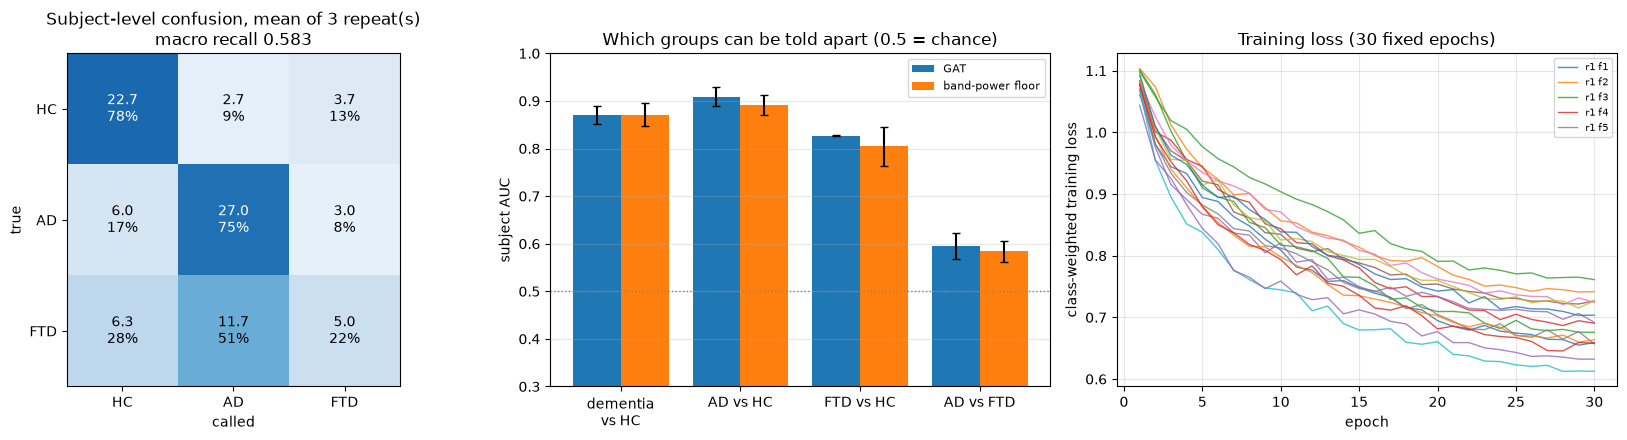

In [9]:
# ===========================================================================
# CELL 9 — RESULTS
# ===========================================================================
def table(title, cols, heads):
    print("=" * 92)
    print(f"{title:37s}" + "".join(f"{h:>11s}" for h in heads))
    print("-" * 92)
    for name, row, sd in [(f"MFE-FCGAT 3-class (lr {LR:g})", P, P_SD),
                          ("band-power logistic regression", FLOOR, FLOOR_SD)]:
        print(f"{name:37s}" + "".join(f"{row[c]:11.4f}" for c in cols))
        if N_REPEATS > 1:
            print(f"{'   +- SD over repeats':37s}" + "".join(f"{sd[c]:11.4f}" for c in cols))
    print("=" * 92)


table("subject level, pooled over 88",
      ["s_macro_recall", "s_recall_HC", "s_recall_AD", "s_recall_FTD", "s_macro_auc", "s_acc"],
      ["macroRec", "rec HC", "rec AD", "rec FTD", "macroAUC", "acc"])
print(f"{'chance':37s}{1 / N_CLASSES:11.4f}\n")
table("which groups can be told apart",
      ["s_dementia_recall", "s_dementia_auc", "s_auc_AD_HC", "s_auc_FTD_HC", "s_auc_AD_FTD"],
      ["dem recall", "dem AUC", "AUC AD-HC", "AUC FTD-HC", "AUC AD-FTD"])
print("dementia = AD + FTD vs HC; its specificity is 'rec HC' above. Pairwise AUC 0.5 = the two groups look the same.")
d = lambda k: P[k] - FLOOR[k]
print(f"\nvs floor: macro recall {d('s_macro_recall'):+.4f}   macro AUC {d('s_macro_auc'):+.4f}   "
      f"AD-FTD AUC {d('s_auc_AD_FTD'):+.4f}   (judge against the SDs; one FTD subject = 0.043 FTD recall)")

# --- subject-level confusion matrix, mean over repeats -------------------------
subs, s_y, _ = subject_probs(np.arange(len(Y)), OOF[0])
S_P    = np.stack([subject_probs(np.arange(len(Y)), OOF[r])[2] for r in range(N_REPEATS)])   # (R, 88, 3)
s_pred = S_P.argmax(2)                                                                        # (R, 88)
CM = pd.DataFrame(np.mean([confusion_matrix(s_y, s_pred[r], labels=CLASSES) for r in range(N_REPEATS)], axis=0),
                  index=[f"true {n}" for n in CLASS_NAMES], columns=[f"called {n}" for n in CLASS_NAMES])
print(f"\nsubject-level confusion matrix, mean over {N_REPEATS} repeat(s) "
      f"(rows = truth; recall = diagonal / row sum)\n{CM.round(1)}")

# --- per-subject calls: probabilities averaged over repeats ---------------------
s_P = S_P.mean(0)
PER_SUBJECT = pd.DataFrame(dict(subject=subs, label=[CLASS_NAMES[c] for c in s_y],
                                called=[CLASS_NAMES[c] for c in s_P.argmax(1)],
                                **{f"p_{n}": s_P[:, c] for c, n in enumerate(CLASS_NAMES)},
                                correct_runs=(s_pred == s_y).sum(0)))
PER_SUBJECT["correct"] = PER_SUBJECT.label == PER_SUBJECT.called
PER_SUBJECT.to_csv(RESULT_DIR / "per_subject.csv", index=False)
print(f"\n{PER_SUBJECT.correct.sum()}/{len(PER_SUBJECT)} subjects correct on repeat-averaged probabilities; "
      f"misclassified (correct_runs = repeats out of {N_REPEATS} in which the subject was called right):")
print(PER_SUBJECT[~PER_SUBJECT.correct].sort_values(["label", "called"]).to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))

# --- plots ---------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
cm = CM.values
cm_norm = cm / cm.sum(1, keepdims=True)
ax[0].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax[0].text(j, i, f"{cm[i, j]:.1f}\n{cm_norm[i, j]:.0%}", ha="center", va="center",
                   color="white" if cm_norm[i, j] > 0.6 else "black")
ax[0].set(xticks=CLASSES, yticks=CLASSES, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
          xlabel="called", ylabel="true",
          title=f"Subject-level confusion, mean of {N_REPEATS} repeat(s)\nmacro recall {P['s_macro_recall']:.3f}")

keys = ["s_dementia_auc", "s_auc_AD_HC", "s_auc_FTD_HC", "s_auc_AD_FTD"]
pos  = np.arange(len(keys))
ax[1].bar(pos - 0.2, [P[k] for k in keys], 0.4, yerr=[P_SD[k] for k in keys], capsize=3, label="GAT")
ax[1].bar(pos + 0.2, [FLOOR[k] for k in keys], 0.4, yerr=[FLOOR_SD[k] for k in keys], capsize=3,
          label="band-power floor")
ax[1].axhline(0.5, color="grey", ls=":", lw=1)
ax[1].set(xticks=pos, xticklabels=["dementia\nvs HC", "AD vs HC", "FTD vs HC", "AD vs FTD"],
          ylim=(0.3, 1.0), ylabel="subject AUC", title="Which groups can be told apart (0.5 = chance)")
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, axis="y")

for (r, f), h in HISTORY.items():
    ax[2].plot(h.epoch, h.train_loss, lw=1, alpha=0.8, label=f"r{r} f{f}" if r == 1 else None)
ax[2].set(xlabel="epoch", ylabel="class-weighted training loss", title=f"Training loss ({EPOCHS} fixed epochs)")
ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(RESULT_DIR / "summary.png", dpi=140)
plt.show()

---
## Ensemble: network + band power (soft vote)

The graph network and the band-power logistic regression make different
mistakes, so averaging their probabilities helps. The weights are equal and
fixed in advance, so nothing is tuned on test subjects. Both models are scored
on the same test subjects. The cell reads the network's saved out-of-fold
probabilities, so after a restart it only needs the cells above it, not
another training run.

In [ ]:
# ===========================================================================
# CELL 10 — ENSEMBLE: GAT + band-power floor (soft vote, no extra training)
# ===========================================================================
NET_OOF = np.load(RESULT_DIR / "oof_prob.npy")
assert NET_OOF.shape == FLOOR_OOF.shape, "run Cell 8 with the same N_REPEATS first"
ENS_OOF = (NET_OOF + FLOOR_OOF) / 2
np.save(RESULT_DIR / "ensemble_oof_prob.npy", ENS_OOF)

cols  = ["s_macro_recall", "s_recall_HC", "s_recall_AD", "s_recall_FTD", "s_macro_auc",
         "s_dementia_auc", "s_auc_AD_FTD"]
heads = ["macroRec", "rec HC", "rec AD", "rec FTD", "macroAUC", "dem AUC", "AD-FTD"]
ENS = {}
print("=" * 114)
print(f"{'subject level, pooled over 88':37s}" + "".join(f"{h:>11s}" for h in heads))
print("-" * 114)
for name, oof in [(f"MFE-FCGAT 3-class (lr {LR:g})", NET_OOF), ("band-power logistic regression", FLOOR_OOF),
                  ("soft vote: GAT + band power", ENS_OOF)]:
    m, sd = mean_sd(pd.DataFrame([score(np.arange(len(Y)), oof[r]) for r in range(N_REPEATS)]))
    ENS[name] = m
    print(f"{name:37s}" + "".join(f"{m[c]:11.4f}" for c in cols))
    if N_REPEATS > 1:
        print(f"{'   +- SD over repeats':37s}" + "".join(f"{sd[c]:11.4f}" for c in cols))
print("=" * 114)
_ = (RESULT_DIR / "ensemble_summary.json").write_text(json.dumps({k: v.to_dict() for k, v in ENS.items()}, indent=2))

---
## Reading the result

- **Lead with macro recall and the confusion matrix.** Per-class recall shows
  where the model fails.
- **Then the pairwise AUCs.** They say which two groups the model can and
  cannot separate. In the first run (1 repeat, validation-selected epochs),
  AD vs HC was 0.90 but AD vs FTD was 0.50, i.e. the model treated AD and FTD
  as one "dementia" group. Dementia vs HC, with its recall, is the screening
  number a clinician cares about first.
- **Quote pooled numbers only, as mean ± SD over repeats.** One FTD subject is
  worth 1/23 = 0.043 of pooled FTD recall, and about 0.2 of a single fold's.
- **Compare with the floor, not with chance alone.** Both are trained on the
  same subjects. A graph model that does not beat multinomial logistic
  regression on band power is not earning its parameters.
- **AD recall here is not the binary AD recall.** In 3-class, an AD subject
  called FTD counts as missed, even though a clinician would still flag them as
  "dementia". Dementia recall counts that case as found.
- **`EPOCHS` was fixed before this protocol saw any test subject.** Changing it
  after reading these results would turn the test folds into a validation set.